# 第 02 关：平均收益的横截面规律

**本关要回答的问题：** 不同类型的股票，长期平均收益是否不同？

"横截面"指在同一时期比较不同资产；与之相对的"时间序列"是看同一资产在不同时期的变化。资产定价最终要解释的，就是平均收益在资产之间的横截面差异。本关先把这种差异找出来，第 03 关再问 CAPM 能不能解释它。

### 两个公司特征
- **规模（size）**：公司股票的总市值 ME（Market Equity）= 股价 × 发行在外股数。Banz（1981）发现小市值股票的平均收益偏高。
- **账面市值比（B/M，Book-to-Market）**：账面权益 BE ÷ 市值 ME。账面权益是资产负债表上的股东权益（资产减负债），市值是市场对这份权益给出的价格。B/M 高，说明市场给的价格相对账面价值低，这类股票俗称**价值股**；B/M 低的俗称**成长股**，因为市场愿意为它预期中的增长付高价。Fama–French（1992）发现，规模和 B/M 两个特征就能刻画平均收益的大部分横截面差异。

为什么这两个特征可能和收益有关？一种解释是风险：小公司和价值股（常常是经营遇到困难的公司）在经济不好时更脆弱，投资者因此要求更高回报。另一种解释是定价偏差：投资者对成长股过于乐观、对价值股过于悲观。本关只描述规律，暂不区分这两种解释。

### 排序组合
单只股票的收益噪声太大，很难看出规律。**排序组合**的做法是：每年 6 月底，按规模把股票分成五档，再独立地按 B/M 分成五档，两两交叉得到 25 个组合。分档的分界点只用纽约证券交易所（NYSE）的股票计算，避免数量众多的微型股决定分界线。每个组合内部按市值加权计算月收益，持有到次年 6 月再重新分组。这样每个组合代表"某一类股票"，组合之间的平均收益差就是特征对应的收益规律。

本关对照 FF1993 的 **Table 2**，样本为 1963-07 至 1991-12，使用月度超额收益。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/course.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from course import (load_raw, load_returns, raw_path, catalog, manifest, style,
                    build_ff3, build_ff5, heatmap25, save_table, paper_note)
from analysis import fit_models, grs_test, model_summary
style()
print('项目目录：', ROOT)

项目目录： E:\Eth data\asset_pricing_quest


In [2]:
display(Markdown(paper_note('ff1993')))

**论文对照：** [Fama & French (1993), Common risk factors in the returns on stocks and bonds](../papers/ff1993_primary_reference.pdf)。准确表号、PDF 页码和复现范围见 [论文表格导航](../papers/TABLE_GUIDE.md)。当前数据版本会与原文历史版本存在差异。

## 1. 25 个组合的平均超额收益
把每个组合的月超额收益在 342 个月上取平均，排成 5×5 的表：行是规模（Small 最小 → Big 最大），列是 B/M（Low BM 最低 → High BM 最高），单位 %/月。热力图用颜色深浅显示同一组数字，颜色越深，平均收益越高。

代码同时计算每个组合的标准差和 `t_mean_iid` 并存入 `results/`。`t_mean_iid` = 均值 ÷（标准差 / √月数），即假设各月收益独立同分布时，均值是它估计误差的多少倍。

,Low BM,2,3,4,High BM
Small,0.3172,0.6631,0.7435,0.8649,0.9897
2,0.3944,0.6435,0.8355,0.8998,0.9850
3,0.4331,0.6494,0.6798,0.8236,0.9249
4,0.4587,0.3659,0.6152,0.7927,0.8838
Big,0.3693,0.3371,0.3542,0.5077,0.5286


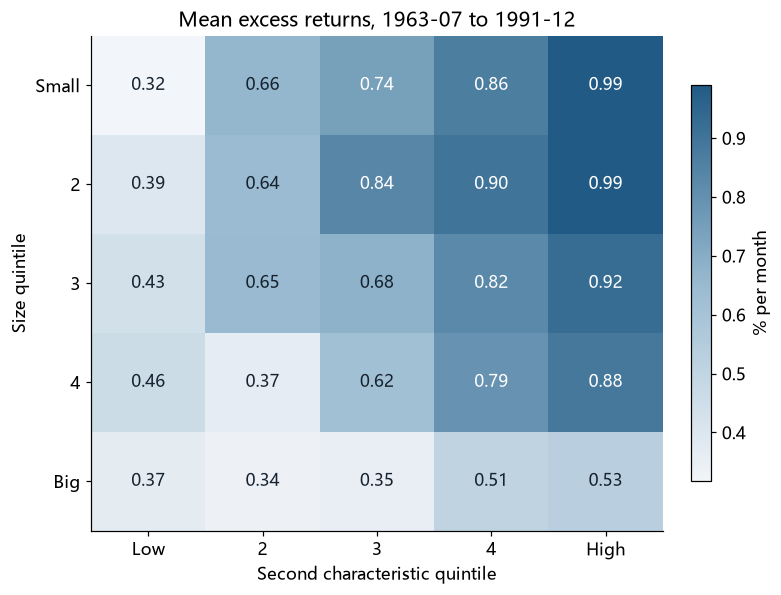

WindowsPath('E:/Eth data/asset_pricing_quest/results/02_ff1993_table2_stock_descriptives.csv')

In [3]:
ff = load_returns('ff3','1963-07','1991-12')
p = load_returns('bm25','1963-07','1991-12')
excess = p.sub(ff.RF, axis=0)
mean_grid = pd.DataFrame((excess.mean()*100).to_numpy().reshape(5,5),
    index=['Small','2','3','4','Big'],columns=['Low BM','2','3','4','High BM'])
display(mean_grid)
heatmap25(excess.mean()*100,'Mean excess returns, 1963-07 to 1991-12','% per month')
plt.show()
descriptive = pd.DataFrame({'mean_excess_pct_month':excess.mean()*100,'sd_pct_month':excess.std()*100,
                            't_mean_iid':excess.mean()/(excess.std()/np.sqrt(len(excess)))})
save_table(descriptive,'02_ff1993_table2_stock_descriptives')

**怎么读：** 两个规律一目了然。
- **价值效应**：每一行从左到右，平均收益基本上升。高 B/M 组合比低 B/M 组合每月多赚约 0.2–0.7 个百分点。
- **规模效应**：除了最低 B/M 那一列，每一列从上到下基本下降，小公司组合的收益更高。

左上角的"小盘成长"组合（Small, Low BM）只有约 0.32%/月，是 25 个组合里最低的。后面几关会反复遇到它。

In [4]:
value_spread = mean_grid.iloc[:, -1] - mean_grid.iloc[:, 0]   # 每个规模组：最高 B/M 减最低 B/M
size_spread = mean_grid.iloc[0] - mean_grid.iloc[-1]          # 每个 B/M 组：最小规模减最大规模
display(pd.DataFrame({'High-minus-Low BM (pct/month)':value_spread}))
display(Markdown(f'**读数：** 在最小规模组，高 B/M 组合比低 B/M 组合平均每月多赚 **{value_spread.iloc[0]:.3f} 个百分点**；在最大规模组只多 **{value_spread.iloc[-1]:.3f}** 个百分点。价值效应在小公司中更强。这些是原始的平均收益差，还没有考虑两类组合承担的市场风险是否不同。'))

,High-minus-Low BM (pct/month)
Small,0.6725
2,0.5906
3,0.4918
4,0.4252
Big,0.1593


**读数：** 在最小规模组，高 B/M 组合比低 B/M 组合平均每月多赚 **0.673 个百分点**；在最大规模组只多 **0.159** 个百分点。价值效应在小公司中更强。这些是原始的平均收益差，还没有考虑两类组合承担的市场风险是否不同。

## 2. 这个价差是不是运气？
342 个月的平均值仍然有估计误差。要判断价差是否可靠地大于零，需要拿均值和它的**标准误**比较。标准误是"均值这个估计值本身的抽样波动大小"：换一段同样长的历史，算出的均值大约会在这个范围内变动。**t 值** = 均值 ÷ 标准误，绝对值大于约 2 时，通常认为在 5% 的水平上显著不为零。

以最小规模组为例：构造"高 B/M 组合减低 B/M 组合"的月收益序列，然后把它对常数 1 回归。常数项的估计值恰好就是样本均值，回归软件会顺便给出标准误和置信区间。

标准误采用 **HAC（heteroskedasticity and autocorrelation consistent，异方差与自相关稳健）** 方法，也叫 Newey–West 标准误。普通标准误假设各月收益互不相关、波动大小不变；而收益序列常有波动聚集（某些年份波动特别大）和轻微的前后相关，HAC 标准误对这两种情况都做了修正。`maxlags=6` 表示允许相隔 6 个月以内的观测彼此相关。

In [5]:
import statsmodels.api as sm
# 最小规模组：SMALL HiBM 减 SMALL LoBM。两边减去的 RF 相同、会抵消，所以直接用原始收益相减
spread = p.iloc[:,4] - p.iloc[:,0]
# 对常数 1 回归：常数项的估计值就是样本均值；cov_type='HAC' 给出 Newey–West 标准误
mean_fit = sm.OLS(spread.to_numpy(), np.ones((len(spread),1))).fit(cov_type='HAC',cov_kwds={'maxlags':6})
ci = mean_fit.conf_int()[0]*100
display(pd.DataFrame({'mean_pct_month':[mean_fit.params[0]*100], 't_HAC6':[mean_fit.tvalues[0]],
                      'ci95_low':[ci[0]],'ci95_high':[ci[1]]}))

,mean_pct_month,t_HAC6,ci95_low,ci95_high
0,0.6725,2.9887,0.2315,1.1136


**怎么读：** `mean_pct_month` 是价差的月均值；`t_HAC6` 是用 6 阶 HAC 标准误算出的 t 值；`ci95_low`、`ci95_high` 是 95% 置信区间的上下限，单位都是 %/月。价差约 0.67 个百分点/月，t 值约 3.0，置信区间不包含 0：小公司中的价值效应在统计上相当可靠。

## 3. 价差从哪里来？
平均收益的差异可能有四种来源：
1. **风险补偿**：价值股承担了更多某种风险；
2. **错误定价**：投资者系统性地看错了某类股票；
3. **样本偶然**：这段历史碰巧如此；
4. **测量方式**：数据构造的细节造成。

排序结果本身无法区分它们。下一关先检验最简单的风险解释：市场 β 能不能解释这些差异。

## 4. 与原文 Table 2 对照
下表把原论文 Table 2 的几个关键数值（单位 %/月）和我们用当前数据重算的结果放在一起：`原文` 是论文印刷的数值，`当前快照` 是本次计算值，`当前减原文` 是两者之差。前三行是三个因子的月均收益，后四行是四个角落组合的月均超额收益。完整原表见本地 PDF 第 12–13 页。

差异有两个来源：French 此后修订过 1963–1991 年的历史数据；原文数值只保留两位小数。模式和量级一致即可，不要求逐位相同。

In [6]:
import json
anchors = json.loads((ROOT/'papers/paper_map.json').read_text(encoding='utf-8'))['numeric_anchors']

rows = []
for a in anchors:
    if a['paper']=='ff1993' and a['table']=='2':
        current = ff[a['key']].mean()*100 if a['metric']=='mean_factor_return' else excess[a['key']].mean()*100
        rows.append({'对象':a['key'],'原文':a['paper_value'],'当前快照':current,'当前减原文':current-a['paper_value']})
comparison = pd.DataFrame(rows)
display(comparison)
save_table(comparison,'02_original_table2_anchors')

,对象,原文,当前快照,当前减原文
0,Mkt-RF,0.43,0.4106,-0.0194
1,SMB,0.27,0.2592,-0.0108
2,HML,0.40,0.3775,-0.0225
3,SMALL LoBM,0.39,0.3172,-0.0728
4,SMALL HiBM,1.01,0.9897,-0.0203
5,BIG LoBM,0.40,0.3693,-0.0307
6,BIG HiBM,0.59,0.5286,-0.0614


WindowsPath('E:/Eth data/asset_pricing_quest/results/02_original_table2_anchors.csv')

## Boss 作答区

选取热力图中的两个组合，提出一个能解释它们收益差异的假说，并说明下一关可以怎样检验其中一部分。

**我的回答：**

（由你填写；本课程未预填答案。）